In [1]:
pip install pybaseball

Note: you may need to restart the kernel to use updated packages.


# 0.0 Install Packages / Set up 

In [31]:
import pandas as pd
import numpy as np

In [3]:
pd.set_option('display.max_columns', None)
from IPython.display import display, HTML


# 1.0 Load Data

https://baseballsavant.mlb.com/csv-docs
https://github.com/jldbc/pybaseball/blob/master/docs/statcast.md


In [72]:

from pybaseball import statcast, cache
cache.enable()

data = statcast(
    start_dt='2023-01-01',
    end_dt='2025-12-31'
)

# Keep only umpire ball/strike calls
data = data[data['description'].isin(['called_strike', 'ball'])]

print(data.shape)

This is a large query, it may take a moment to complete
Skipping offseason dates
Skipping offseason dates
Skipping offseason dates
Skipping offseason dates


  0%|          | 0/738 [00:00<?, ?it/s]/opt/anaconda3/lib/python3.12/site-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
  0%|          | 1/738 [00:01<17:50,  1.45s/it]/opt/anaconda3/lib/python3.12/site-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and catch exceptions explicitly instead
  data_copy[column] = data_copy[column].apply(pd.to_datetime, errors='ignore', format=date_format)
/opt/anaconda3/lib/python3.12/site-packages/pybaseball/datahelpers/postprocessing.py:59: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_datetime without passing `errors` and

(1141019, 119)


In [73]:
# Display all column names in a scrollable format
display(HTML('<div style="height: 200px; overflow-y: scroll;">{}</div>'.format('<br>'.join(data.columns))))

In [74]:
data.head()

,pitch_type,game_date,release_speed,release_pos_x,release_pos_z,player_name,batter,pitcher,events,description,spin_dir,spin_rate_deprecated,break_angle_deprecated,break_length_deprecated,zone,des,game_type,stand,p_throws,home_team,away_team,type,hit_location,bb_type,balls,strikes,game_year,pfx_x,pfx_z,plate_x,plate_z,on_3b,on_2b,on_1b,outs_when_up,inning,inning_topbot,hc_x,hc_y,tfs_deprecated,tfs_zulu_deprecated,umpire,sv_id,vx0,vy0,vz0,ax,ay,az,sz_top,sz_bot,hit_distance_sc,launch_speed,launch_angle,effective_speed,release_spin_rate,release_extension,game_pk,fielder_2,fielder_3,fielder_4,fielder_5,fielder_6,fielder_7,fielder_8,fielder_9,release_pos_y,estimated_ba_using_speedangle,estimated_woba_using_speedangle,woba_value,woba_denom,babip_value,iso_value,launch_speed_angle,at_bat_number,pitch_number,pitch_name,home_score,away_score,bat_score,fld_score,post_away_score,post_home_score,post_bat_score,post_fld_score,if_fielding_alignment,of_fielding_alignment,spin_axis,delta_home_win_exp,delta_run_exp,bat_speed,swing_length,miss_distance,estimated_slg_using_speedangle,delta_pitcher_run_exp,hyper_speed,home_score_diff,bat_score_diff,home_win_exp,bat_win_exp,age_pit_legacy,age_bat_legacy,age_pit,age_bat,n_thruorder_pitcher,n_priorpa_thisgame_player_at_bat,pitcher_days_since_prev_game,batter_days_since_prev_game,pitcher_days_until_next_game,batter_days_until_next_game,api_break_z_with_gravity,api_break_x_arm,api_break_x_batter_in,arm_angle,attack_angle,attack_direction,swing_path_tilt,intercept_ball_minus_batter_pos_x_inches,intercept_ball_minus_batter_pos_y_inches
45,CU,2025-11-01,80.3,-1.7,5.45,"Yamamoto, Yoshinobu",672386,808967,NaN,called_strike,<NA>,<NA>,<NA>,<NA>,4,NaN,W,R,R,TOR,LAD,S,<NA>,NaN,0,1,2025,1.36,-1.25,-0.279088,1.962539,665489,<NA>,680718,1,11,Bot,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,0.56166,-116.768446,1.472301,12.095261,26.350181,-44.003006,2.915852,1.373793,<NA>,<NA>,<NA>,79.7,2970,6.4,813024,669257,518692,808975,571970,605141,571771,681909,681624,54.15,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,99,2,Curveball,4,5,4,5,5,4,4,5,Standard,Standard,42,-0.066,-0.073,<NA>,<NA>,<NA>,<NA>,0.073,<NA>,-1,-1,0.426,0.426,26,26,27,27,2,5,1,1,<NA>,<NA>,4.85,-1.36,-1.36,48.1,<NA>,<NA>,<NA>,<NA>,<NA>
57,FS,2025-11-01,90.8,-2.02,5.27,"Yamamoto, Yoshinobu",680718,808967,NaN,ball,<NA>,<NA>,<NA>,<NA>,11,NaN,W,L,R,TOR,LAD,B,<NA>,NaN,2,0,2025,-0.23,0.47,-0.455981,3.869439,665489,<NA>,<NA>,1,11,Bot,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,4.422862,-132.18685,1.43482,-3.694161,29.396866,-27.246427,3.719998,1.759224,<NA>,<NA>,<NA>,91.0,1360,6.5,813024,669257,518692,808975,571970,605141,571771,681909,681624,54.01,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,98,3,Split-Finger,4,5,4,5,5,4,4,5,Strategic,Standard,240,0.013,0.064,<NA>,<NA>,<NA>,<NA>,-0.064,<NA>,-1,-1,0.436,0.436,26,25,27,26,1,5,1,1,<NA>,<NA>,2.3,0.23,-0.23,38.0,<NA>,<NA>,<NA>,<NA>,<NA>
61,FS,2025-11-01,91.7,-2.01,5.26,"Yamamoto, Yoshinobu",680718,808967,NaN,ball,<NA>,<NA>,<NA>,<NA>,11,NaN,W,L,R,TOR,LAD,B,<NA>,NaN,1,0,2025,-0.66,0.1,-1.083276,2.803786,665489,<NA>,<NA>,1,11,Bot,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,3.766941,-133.55072,-0.587893,-8.691656,28.767832,-31.054278,3.72,1.753611,<NA>,<NA>,<NA>,92.0,1285,6.4,813024,669257,518692,808975,571970,605141,571771,681909,681624,54.09,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,98,2,Split-Finger,4,5,4,5,5,4,4,5,Strategic,Standard,239,0.008,0.037,<NA>,<NA>,<NA>,<NA>,-0.037,<NA>,-1,-1,0.428,0.428,26,25,27,26,1,5,1,1,<NA>,<NA>,2.6,0.66,-0.66,40.3,<NA>,<NA>,<NA>,<NA>,<NA>
68,FS,2025-11-01,90.9,-2.03,5.22,"Yamamoto, Yoshinobu",680718,808967,NaN,ball,<NA>,<NA>,<NA>,<NA>,1,NaN,W,L,R,TOR,LAD,B,<NA>,NaN,0,0,2025,-0.42,0.55,-0.765755,3.221684,665489,<NA>,<NA>,1,11,Bot,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,4.062758,-132.25844,-0.249732,-5.804733,29.554675,-25.878484,3.605711,1.654127,<NA>,<NA>,<NA>,90.9,1133,6.4,813024,669257,518692,808975,571970,605141,571771,681909,681624,54.13,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,98,1,Split-Finger,4,5,4,5,5,4,4,5,Strategic,Standard,247,0.004,0.026,<NA>,<NA>,<NA>,<N

In [75]:
data.describe()

,game_date,release_speed,release_pos_x,release_pos_z,batter,pitcher,spin_dir,spin_rate_deprecated,break_angle_deprecated,break_length_deprecated,zone,hit_location,balls,strikes,game_year,pfx_x,pfx_z,plate_x,plate_z,on_3b,on_2b,on_1b,outs_when_up,inning,hc_x,hc_y,tfs_deprecated,tfs_zulu_deprecated,umpire,sv_id,vx0,vy0,vz0,ax,ay,az,sz_top,sz_bot,hit_distance_sc,launch_speed,launch_angle,effective_speed,release_spin_rate,release_extension,game_pk,fielder_2,fielder_3,fielder_4,fielder_5,fielder_6,fielder_7,fielder_8,fielder_9,release_pos_y,estimated_ba_using_speedangle,estimated_woba_using_speedangle,woba_value,woba_denom,babip_value,iso_value,launch_speed_angle,at_bat_number,pitch_number,home_score,away_score,bat_score,fld_score,post_away_score,post_home_score,post_bat_score,post_fld_score,spin_axis,delta_home_win_exp,delta_run_exp,bat_speed,swing_length,miss_distance,estimated_slg_using_speedangle,delta_pitcher_run_exp,hyper_speed,home_score_diff,bat_score_diff,home_win_exp,bat_win_exp,age_pit_legacy,age_bat_legacy,age_pit,age_bat,n_thruorder_pitcher,n_priorpa_thisgame_player_at_bat,pitcher_days_since_prev_game,batter_days_since_prev_game,pitcher_days_until_next_game,batter_days_until_next_game,api_break_z_with_gravity,api_break_x_arm,api_break_x_batter_in,arm_angle,attack_angle,attack_direction,swing_path_tilt,intercept_ball_minus_batter_pos_x_inches,intercept_ball_minus_batter_pos_y_inches
count,1141019,1121129.0,1121129.0,1121129.0,1141019.0,1141019.0,0.0,0.0,0.0,0.0,1121132.0,32517.0,1141019.0,1141019.0,1141019.0,1121070.0,1121128.0,1121132.0,1121132.0,95472.0,195028.0,327521.0,1141019.0,1141019.0,0.0,0.0,0.0,0.0,0.0,0.0,1121129.0,1121129.0,1121129.0,1121129.0,1121129.0,1121129.0,1121132.0,1121132.0,0.0,0.0,0.0,1120046.0,1116295.0,1119971.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1121129.0,0.0,70989.0,77552.0,71769.0,77552.0,77552.0,0.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1116292.0,1141019.0,1141004.0,0.0,0.0,0.0,0.0,1141004.0,217.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1030705.0,1070491.0,1034812.0,1071411.0,1121069.0,1121070.0,1121070.0,1077670.0,0.0,0.0,0.0,0.0,0.0
mean,2024-06-25 00:07:52.125354496,89.163394,-0.840618,5.764474,643168.862993,637654.099915,<NA>,<NA>,<NA>,<NA>,10.299026,2.000738,0.734418,0.712655,2023.999946,-0.119173,0.591154,0.051861,2.327319,645012.163189,644850.34795,643673.299859,0.970214,4.9308,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,2.512943,-129.663844,-3.667805,-2.297553,27.20254,-24.118503,3.397161,1.600143,<NA>,<NA>,<NA>,89.356763,2265.007979,6.433813,747619.144543,636460.368986,628370.599812,650650.021458,644028.980065,652383.353754,651582.249176,664683.408126,644880.397857,54.066219,<NA>,0.406979,0.406703,0.989229,0.0,0.0,<NA>,38.332622,2.533702,2.167095,2.334429,2.219563,2.28196,2.335285,2.167966,2.22129,2.28196,176.316886,0.000072,0.017978,<NA>,<NA>,<NA>,<NA>,-0.017978,88.078341,-0.167335,-0.062397,0.504903,0.509966,28.876401,27.968585,29.401407,28.512702,1.462965,1.496398,6.029982,1.680265,6.173074,1.657731,2.327243,0.332014,-0.102196,38.049828,<NA>,<NA>,<NA>,<NA>,<NA>
min,2023-03-15 00:00:00,21.7,-5.14,0.76,408234.0,425794.0,<NA>,<NA>,<NA>,<NA>,1.0,1.0,0.0,0.0,2023.0,-2.95,-2.14,-11.365394,-57.60148,408234.0,408234.0,408234.0,0.0,1.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,-20.9275,-152.524544,-29.291284,-32.368741,1.549108,-51.284004,2.506867,0.758932,<NA>,<NA>,<NA>,28.7,14.0,2.8,716352.0,444489.0,408234.0,456781.0,446334.0,462101.0,444482.0,453568.0,444482.0,50.78,<NA>,0.0,0.0,0.0,0.0,0.0,<NA>,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.355,-0.451,<NA>,<NA>,<NA>,<NA>,-0.73,88.0,-25.0,-25.0,0.0,0.001,19.0,17.0,20.0,18.0,1.0,0.0,0.0,0.0,0.0,0.0,0.12,-2.95,-2.95,-70.7,<NA>,<NA>,<NA>,<NA>,<NA>
25%,2023-08-16 00:00:00,84.8,-2.16,5.49,621439.0,607259.0,<NA>,<NA>,<NA>,<NA>,8.0,2.0,0.0,0.0,2023.0,-0.9,0.14,-0.696089,1.545233,621566.0,621566

# 1.1 Data Cleaning 
- load player names (currently numeric key)
- hot encode variables 

- outcome is : description

In [76]:
data['description'].unique()

array(['called_strike', 'ball'], dtype=object)

In [77]:
data['type'].unique() #S = strike, B = Ball, X = Hit

array(['S', 'B', 'X'], dtype=object)

In [78]:
data.describe()

,game_date,release_speed,release_pos_x,release_pos_z,batter,pitcher,spin_dir,spin_rate_deprecated,break_angle_deprecated,break_length_deprecated,zone,hit_location,balls,strikes,game_year,pfx_x,pfx_z,plate_x,plate_z,on_3b,on_2b,on_1b,outs_when_up,inning,hc_x,hc_y,tfs_deprecated,tfs_zulu_deprecated,umpire,sv_id,vx0,vy0,vz0,ax,ay,az,sz_top,sz_bot,hit_distance_sc,launch_speed,launch_angle,effective_speed,release_spin_rate,release_extension,game_pk,fielder_2,fielder_3,fielder_4,fielder_5,fielder_6,fielder_7,fielder_8,fielder_9,release_pos_y,estimated_ba_using_speedangle,estimated_woba_using_speedangle,woba_value,woba_denom,babip_value,iso_value,launch_speed_angle,at_bat_number,pitch_number,home_score,away_score,bat_score,fld_score,post_away_score,post_home_score,post_bat_score,post_fld_score,spin_axis,delta_home_win_exp,delta_run_exp,bat_speed,swing_length,miss_distance,estimated_slg_using_speedangle,delta_pitcher_run_exp,hyper_speed,home_score_diff,bat_score_diff,home_win_exp,bat_win_exp,age_pit_legacy,age_bat_legacy,age_pit,age_bat,n_thruorder_pitcher,n_priorpa_thisgame_player_at_bat,pitcher_days_since_prev_game,batter_days_since_prev_game,pitcher_days_until_next_game,batter_days_until_next_game,api_break_z_with_gravity,api_break_x_arm,api_break_x_batter_in,arm_angle,attack_angle,attack_direction,swing_path_tilt,intercept_ball_minus_batter_pos_x_inches,intercept_ball_minus_batter_pos_y_inches
count,1141019,1121129.0,1121129.0,1121129.0,1141019.0,1141019.0,0.0,0.0,0.0,0.0,1121132.0,32517.0,1141019.0,1141019.0,1141019.0,1121070.0,1121128.0,1121132.0,1121132.0,95472.0,195028.0,327521.0,1141019.0,1141019.0,0.0,0.0,0.0,0.0,0.0,0.0,1121129.0,1121129.0,1121129.0,1121129.0,1121129.0,1121129.0,1121132.0,1121132.0,0.0,0.0,0.0,1120046.0,1116295.0,1119971.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1121129.0,0.0,70989.0,77552.0,71769.0,77552.0,77552.0,0.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1116292.0,1141019.0,1141004.0,0.0,0.0,0.0,0.0,1141004.0,217.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1141019.0,1030705.0,1070491.0,1034812.0,1071411.0,1121069.0,1121070.0,1121070.0,1077670.0,0.0,0.0,0.0,0.0,0.0
mean,2024-06-25 00:07:52.125354496,89.163394,-0.840618,5.764474,643168.862993,637654.099915,<NA>,<NA>,<NA>,<NA>,10.299026,2.000738,0.734418,0.712655,2023.999946,-0.119173,0.591154,0.051861,2.327319,645012.163189,644850.34795,643673.299859,0.970214,4.9308,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,2.512943,-129.663844,-3.667805,-2.297553,27.20254,-24.118503,3.397161,1.600143,<NA>,<NA>,<NA>,89.356763,2265.007979,6.433813,747619.144543,636460.368986,628370.599812,650650.021458,644028.980065,652383.353754,651582.249176,664683.408126,644880.397857,54.066219,<NA>,0.406979,0.406703,0.989229,0.0,0.0,<NA>,38.332622,2.533702,2.167095,2.334429,2.219563,2.28196,2.335285,2.167966,2.22129,2.28196,176.316886,0.000072,0.017978,<NA>,<NA>,<NA>,<NA>,-0.017978,88.078341,-0.167335,-0.062397,0.504903,0.509966,28.876401,27.968585,29.401407,28.512702,1.462965,1.496398,6.029982,1.680265,6.173074,1.657731,2.327243,0.332014,-0.102196,38.049828,<NA>,<NA>,<NA>,<NA>,<NA>
min,2023-03-15 00:00:00,21.7,-5.14,0.76,408234.0,425794.0,<NA>,<NA>,<NA>,<NA>,1.0,1.0,0.0,0.0,2023.0,-2.95,-2.14,-11.365394,-57.60148,408234.0,408234.0,408234.0,0.0,1.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,-20.9275,-152.524544,-29.291284,-32.368741,1.549108,-51.284004,2.506867,0.758932,<NA>,<NA>,<NA>,28.7,14.0,2.8,716352.0,444489.0,408234.0,456781.0,446334.0,462101.0,444482.0,453568.0,444482.0,50.78,<NA>,0.0,0.0,0.0,0.0,0.0,<NA>,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.355,-0.451,<NA>,<NA>,<NA>,<NA>,-0.73,88.0,-25.0,-25.0,0.0,0.001,19.0,17.0,20.0,18.0,1.0,0.0,0.0,0.0,0.0,0.0,0.12,-2.95,-2.95,-70.7,<NA>,<NA>,<NA>,<NA>,<NA>
25%,2023-08-16 00:00:00,84.8,-2.16,5.49,621439.0,607259.0,<NA>,<NA>,<NA>,<NA>,8.0,2.0,0.0,0.0,2023.0,-0.9,0.14,-0.696089,1.545233,621566.0,621566

# Create outcome variable - Binary Target Variable
# 1. We only need value that are called strike or ball
# 2. Determine if pitch crossed in strike zone, what is expected 
# 3. Determine if pitch outcome matches 2 

Inside zone + called strike = correct
Outside zone + ball = correct
Inside zone + ball = incorrect
Outside zone + called strike = incorrect

In [79]:
#called pitches only 
df = data[data['description'].isin(['called_strike', 'ball'])].copy()

In [80]:
df.shape

(1141019, 119)

In [82]:
x = -0.83
y = 0.83
df = df.dropna(subset=['plate_x', 'plate_z', 'sz_bot', 'sz_top'])

df['expected'] = (
    df['plate_x'].between(x,y) &
    df['plate_z'].between(df['sz_bot'], df['sz_top'])
).astype(int)

In [83]:
df['expected'].describe


<bound method NDFrame.describe of 45      1
57      0
61      0
68      1
86      0
       ..
820     0
918     0
1059    1
1083    1
1329    0
Name: expected, Length: 1121132, dtype: int64>

In [84]:
# if called strike 1 if ball 0 
df['outcome'] = (
    df['description'] == 'called_strike'
).astype(int)

In [85]:
# do expected & call match 
df['target'] = (
    df['outcome'] != df['expected']
).astype(int)

In [86]:
print(df['target'].value_counts())
print(df['target'].value_counts(normalize=True))

target
0    1029474
1      91658
Name: count, dtype: int64
target
0    0.918245
1    0.081755
Name: proportion, dtype: float64


In [87]:
pd.crosstab(df['expected'], df['outcome'])


outcome,0,1
expected,,
0,727670,66228
1,25430,301804


In [88]:
# list of columns to use 
# pitch_type
# game_date
# release_speed
# release_pos_x
# release_pos_z
# player_name
# batter
# pitcher
# events
# description
# spin_dir
# spin_rate_deprecated
# break_angle_deprecated
# break_length_deprecated
# zone
# des
# game_type
# stand
# p_throws
# home_team
# away_team
# type
# hit_location
# bb_type
# balls
# strikes
# game_year
# pfx_x
# pfx_z
# plate_x
# plate_z
# on_3b
# on_2b
# on_1b
# outs_when_up
# inning
# inning_topbot
# hc_x
# hc_y
# tfs_deprecated
# tfs_zulu_deprecated
# umpire
# sv_id
# vx0
# vy0
# vz0
# ax
# ay
# az
# sz_top
# sz_bot
# hit_distance_sc
# launch_speed
# launch_angle
# effective_speed
# release_spin_rate
# release_extension
# game_pk
# fielder_2
# fielder_3
# fielder_4
# fielder_5
# fielder_6
# fielder_7
# fielder_8
# fielder_9
# release_pos_y
# estimated_ba_using_speedangle
# estimated_woba_using_speedangle
# woba_value
# woba_denom
# babip_value
# iso_value
# launch_speed_angle
# at_bat_number
# pitch_number
# pitch_name
# home_score
# away_score
# bat_score
# fld_score
# post_away_score
# post_home_score
# post_bat_score
# post_fld_score
# if_fielding_alignment
# of_fielding_alignment
# spin_axis
# delta_home_win_exp
# delta_run_exp
# bat_speed
# swing_length
# miss_distance
# estimated_slg_using_speedangle
# delta_pitcher_run_exp
# hyper_speed
# home_score_diff
# bat_score_diff
# home_win_exp
# bat_win_exp
# age_pit_legacy
# age_bat_legacy
# age_pit
# age_bat
# n_thruorder_pitcher
# n_priorpa_thisgame_player_at_bat
# pitcher_days_since_prev_game
# batter_days_since_prev_game
# pitcher_days_until_next_game
# batter_days_until_next_game
# api_break_z_with_gravity
# api_break_x_arm
# api_break_x_batter_in
# arm_angle
# attack_angle
# attack_direction
# swing_path_tilt
# intercept_ball_minus_batter_pos_x_inches
# intercept_ball_minus_batter_pos_y_inches

f_data = [
    'plate_x',
    'plate_z',
    'sz_top',
    'sz_bot',
    'release_speed',
    'balls',
    'strikes',
    'pitch_type',
    'stand',
    'p_throws'
]

target_col = 'target'
cat_col = ['pitch_type', 'stand','p_throws']
#categorical variables
num_col = [col for col in f_data if col not in cat_col] #numeric variables

In [89]:
X_data = df[f_data].copy()
Y_data = df[target_col].copy()

In [90]:
X_data.head()

,plate_x,plate_z,sz_top,sz_bot,release_speed,balls,strikes,pitch_type,stand,p_throws
45,-0.279088,1.962539,2.915852,1.373793,80.3,0,1,CU,R,R
57,-0.455981,3.869439,3.719998,1.759224,90.8,2,0,FS,L,R
61,-1.083276,2.803786,3.72,1.753611,91.7,1,0,FS,L,R
68,-0.765755,3.221684,3.605711,1.654127,90.9,0,0,FS,L,R
86,-1.104643,3.130736,3.669999,1.512876,91.3,2,2,FS,R,R


# Pre-processing 
1. determine categorical vs continuous fields 
2. check for missing values
3. check for outliers
4. handle missing/outliers - continous = median, categorical separate category
5. examine target distribution - what is the outcome distribution 
6. transformation (encode catgorical)
7. correlation/distribution plots 
8. train test 80 / 20 


In [91]:
print(X_data.isnull().sum().sort_values(ascending=False))

# no missing values

release_speed    3
plate_x          0
plate_z          0
sz_top           0
sz_bot           0
balls            0
strikes          0
pitch_type       0
stand            0
p_throws         0
dtype: int64


In [92]:
for col in num_col:
    Q1 = X_data[col].quantile(0.25)
    Q3 = X_data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = X_data[
        (X_data[col] < lower_bound) |
        (X_data[col] > upper_bound)]

In [93]:
outliers.shape #no outliers

(0, 10)

In [94]:
# numeric replace with median
for col in num_col:
    X_data[col] = X_data[col].fillna(X_data[col].median())

# categorical separate category for missing
for col in cat_col:
    X_data[col] = X_data[col].fillna('Missing')

In [95]:
print(Y_data.value_counts()) # get counts 2066
print(Y_data.value_counts(normalize=True) * 100) # 170 

target
0    1029474
1      91658
Name: count, dtype: int64
target
0    91.824513
1     8.175487
Name: proportion, dtype: float64


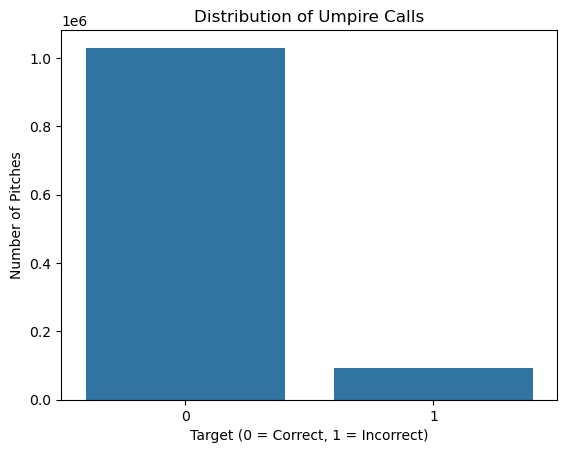

In [96]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x=Y_data)
plt.title('Distribution of Umpire Calls')
plt.xlabel('Target (0 = Correct, 1 = Incorrect)')
plt.ylabel('Number of Pitches')
plt.show()

In [97]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoded_cat = encoder.fit_transform(X_data[cat_col])

encoded_df = pd.DataFrame(
    encoded_cat,
    columns=encoder.get_feature_names_out(cat_col),
    index=X_data.index
)

X_data_transformed = pd.concat(
    [X_data[num_col], encoded_df],
    axis=1
)

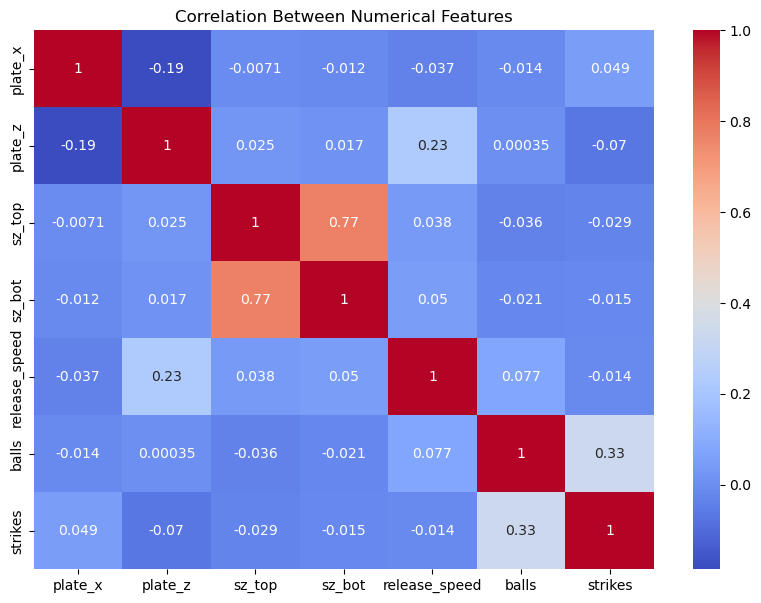

In [98]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    X_data[num_col].corr(),
    annot=True,
    cmap='coolwarm',
)

plt.title('Correlation Between Numerical Features')
plt.show()

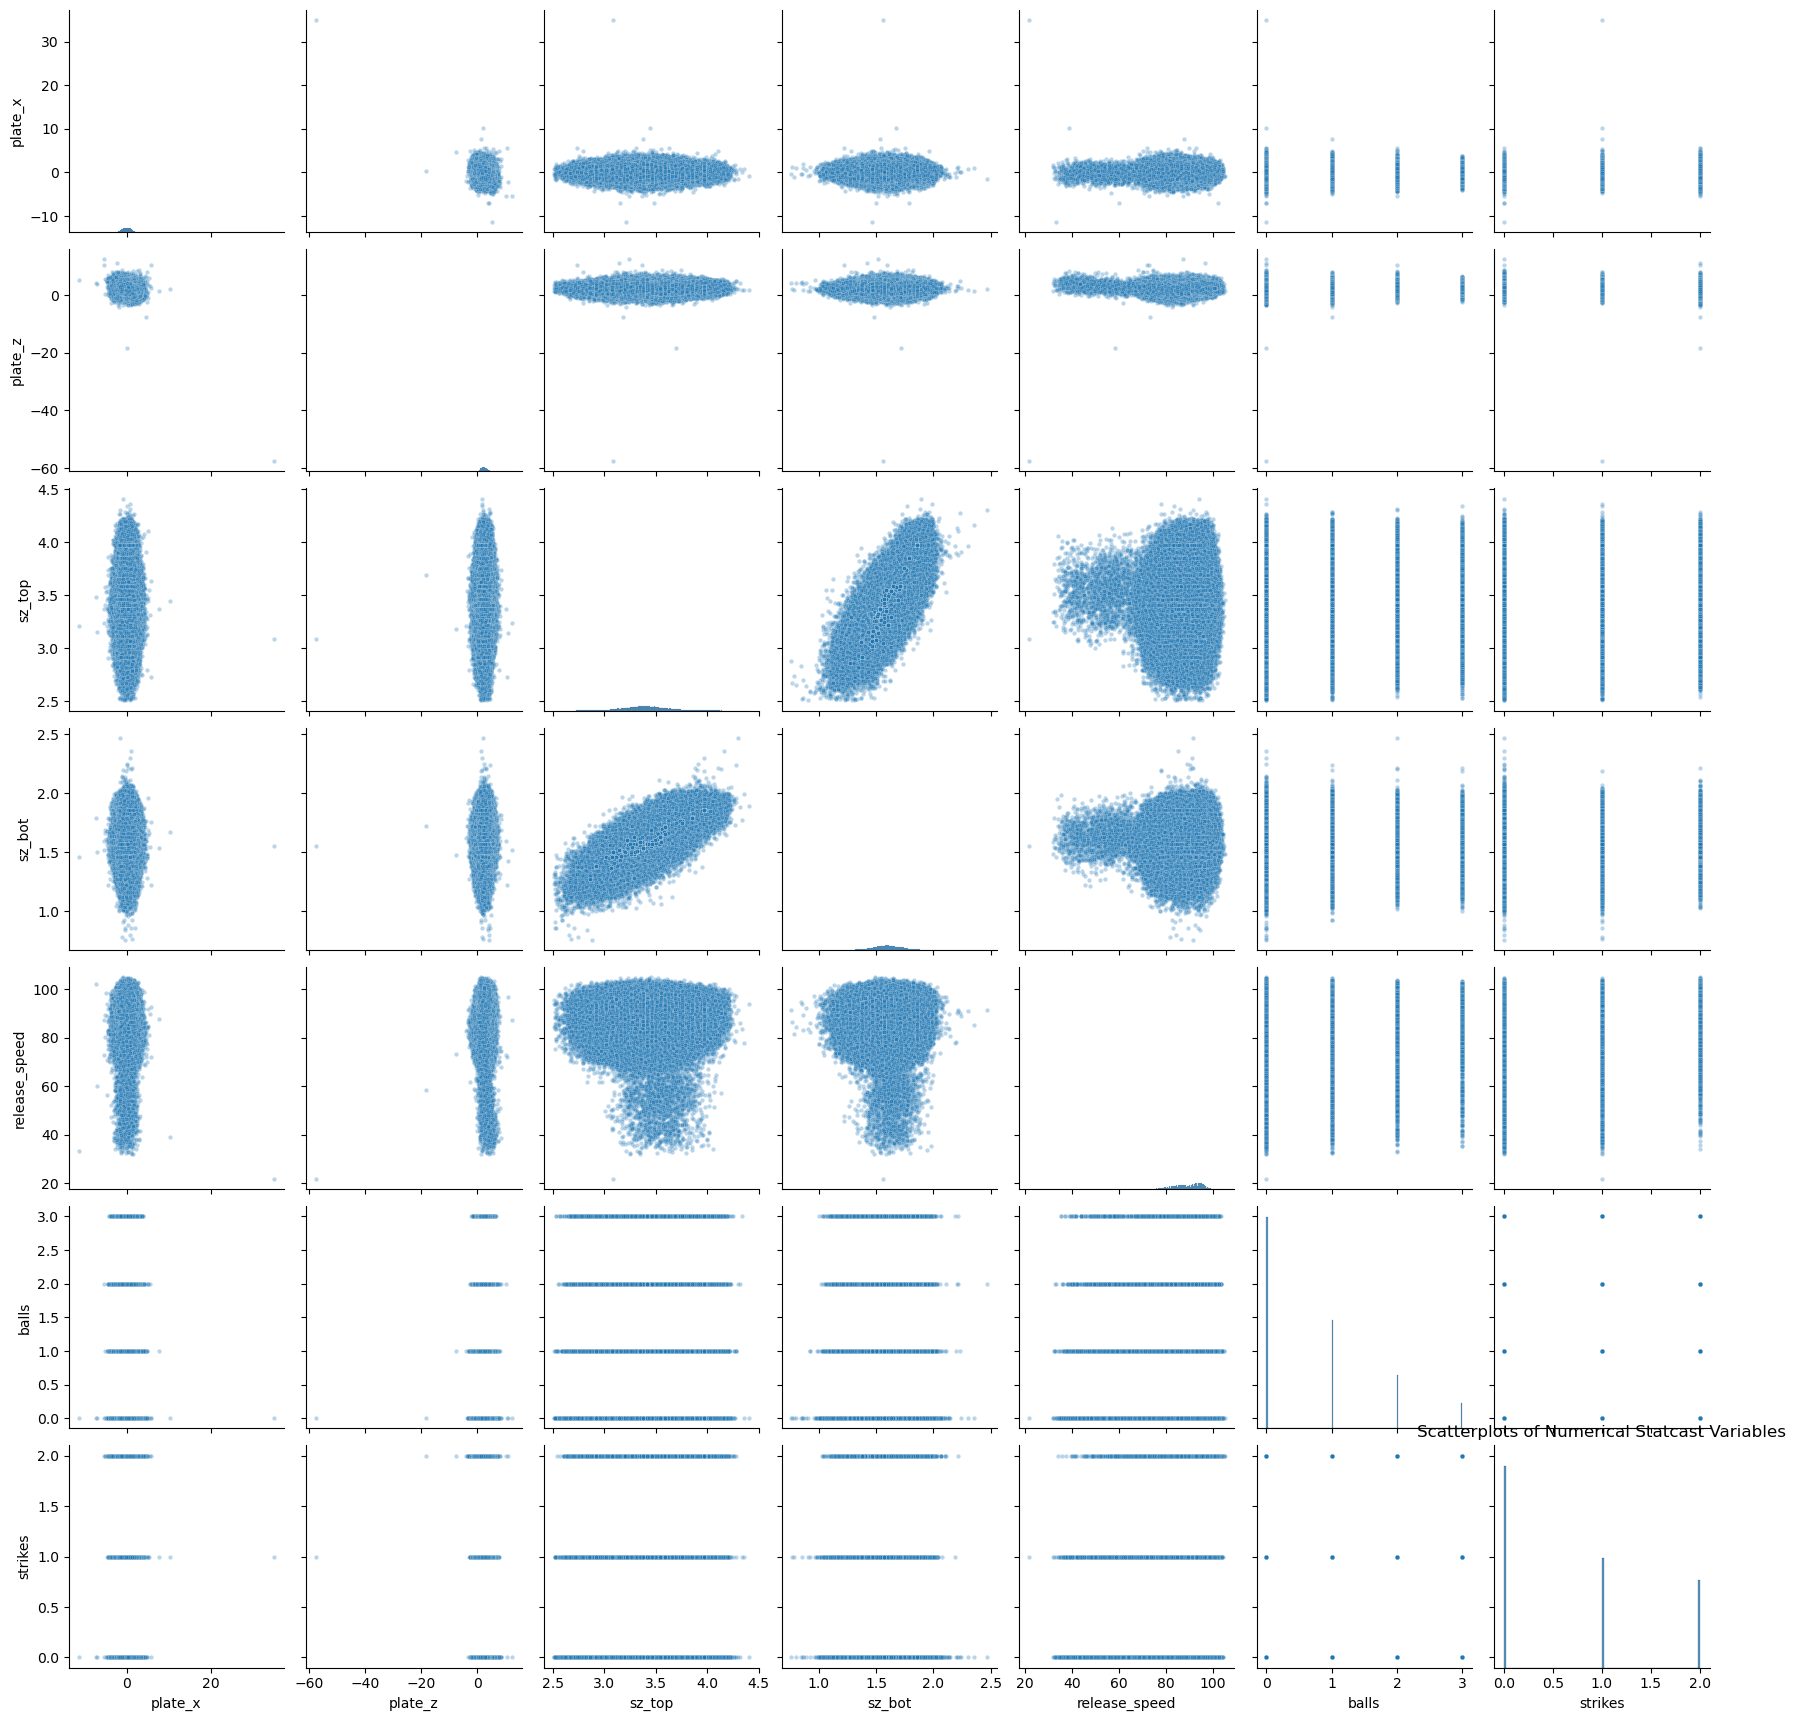

In [99]:
sns.pairplot(
    X_data[num_col],
    diag_kind='hist',
    plot_kws={'alpha': 0.3, 's': 10}
)

plt.title('Scatterplots of Numerical Statcast Variables')
plt.show()

# Train /Test Split 

In [100]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_data_transformed,
    Y_data,
    test_size=0.2,
    random_state=42,
    stratify=Y_data
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (896905, 28)
Testing set: (224227, 28)


# round 1 fit model on existing variable, evaluate model 
# round 2 fit model on feature engineering variables + additional variables, evalulate model 
# round 3 tuning + different models + additional model metrics 
# # model interpretation - feature importance

In [101]:
# start template for model fit

In [102]:

from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000,class_weight='balanced',
    random_state=42) # needed to add in balanced, we have a class imbalance

lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

In [103]:
print(y_train.value_counts(normalize=True))
print(pd.Series(y_pred_lr).value_counts())

target
0    0.918246
1    0.081754
Name: proportion, dtype: float64
1    118890
0    105337
Name: count, dtype: int64


In [104]:
print("Actual:")
print(pd.Series(y_test).value_counts())

print("\nPredicted:")
print(pd.Series(y_pred_lr).value_counts())

Actual:
target
0    205895
1     18332
Name: count, dtype: int64

Predicted:
1    118890
0    105337
Name: count, dtype: int64


In [105]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, y_pred_lr))

[[ 98828 107067]
 [  6509  11823]]


In [106]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.94      0.48      0.64    205895
           1       0.10      0.64      0.17     18332

    accuracy                           0.49    224227
   macro avg       0.52      0.56      0.40    224227
weighted avg       0.87      0.49      0.60    224227



# stop template for model fit

In [107]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [108]:
models = {
    'Logistic Regression': (y_pred_lr, y_prob_lr),
    ## add more models here 
}

results = []

for name, (pred, prob) in models.items():

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1': f1_score(y_test, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy  Precision  Recall      F1  ROC-AUC
0  Logistic Regression    0.4935     0.0994  0.6449  0.1723    0.585


In [109]:
print("Actual:")
print(pd.Series(y_test).value_counts())

print("\nPredicted:")
print(pd.Series(y_pred_lr).value_counts())

Actual:
target
0    205895
1     18332
Name: count, dtype: int64

Predicted:
1    118890
0    105337
Name: count, dtype: int64
